In [26]:
import pandas as pd
from pathlib import Path

url = "https://raw.githubusercontent.com/adgsenpai/IBM-DataScience-SpaceX-Capstone/main/dataset_part_1.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully!
Rows and columns: (90, 17)


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04,Falcon 9,NaN,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2012-05-22,Falcon 9,525.0,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
2,3,2013-03-01,Falcon 9,677.0,ISS,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857
3,4,2013-09-29,Falcon 9,500.0,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093
4,5,2013-12-03,Falcon 9,3170.0,GTO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857


In [27]:
data_dir = Path("../data")
data_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(data_dir / "dataset_part_1.csv", index=False)

print("Backup dataset saved successfully!")

Backup dataset saved successfully!


In [28]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset dimensions: (90, 17)

Column names:
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude']

First 5 rows:


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04,Falcon 9,NaN,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2012-05-22,Falcon 9,525.0,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
2,3,2013-03-01,Falcon 9,677.0,ISS,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857
3,4,2013-09-29,Falcon 9,500.0,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093
4,5,2013-12-03,Falcon 9,3170.0,GTO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   FlightNumber    90 non-null     int64  
 1   Date            90 non-null     object 
 2   BoosterVersion  90 non-null     object 
 3   PayloadMass     85 non-null     float64
 4   Orbit           90 non-null     object 
 5   LaunchSite      90 non-null     object 
 6   Outcome         90 non-null     object 
 7   Flights         90 non-null     int64  
 8   GridFins        90 non-null     bool   
 9   Reused          90 non-null     bool   
 10  Legs            90 non-null     bool   
 11  LandingPad      64 non-null     object 
 12  Block           90 non-null     float64
 13  ReusedCount     90 non-null     int64  
 14  Serial          90 non-null     object 
 15  Longitude       90 non-null     float64
 16  Latitude        90 non-null     float64
dtypes: bool(3), flo

In [29]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values[missing_values > 0])

print("\nDuplicate rows:", df.duplicated().sum())

Missing values in each column:


PayloadMass     5
LandingPad     26
dtype: int64


Duplicate rows: 0


In [30]:
from pathlib import Path

summary_dir = Path("../data")
summary_dir.mkdir(parents=True, exist_ok=True)

summary = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Values": df.isnull().sum().values
})

summary.to_csv(summary_dir / "dataset_summary.csv", index=False)

print("Dataset summary saved successfully!")

Dataset summary saved successfully!


In [31]:
# Create a copy so the original data remains unchanged
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Remove extra spaces from column names
df_clean.columns = df_clean.columns.str.strip()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

display(df_clean.head())

Original dataset shape: (90, 17)
Cleaned dataset shape: (90, 17)


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04,Falcon 9,NaN,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2012-05-22,Falcon 9,525.0,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
2,3,2013-03-01,Falcon 9,677.0,ISS,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857
3,4,2013-09-29,Falcon 9,500.0,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093
4,5,2013-12-03,Falcon 9,3170.0,GTO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857


In [32]:
missing = df_clean.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(df_clean) * 100).round(2)
})

display(missing_report[missing_report["Missing_Count"] > 0])

,Missing_Count,Missing_Percentage
PayloadMass,5,5.56
LandingPad,26,28.89


In [33]:
print("Column data types:")
display(df_clean.dtypes.to_frame(name="Data_Type"))

print("\nDataset summary:")
display(df_clean.describe(include="all").T)

Column data types:


,Data_Type
FlightNumber,int64
Date,object
BoosterVersion,object
PayloadMass,float64
Orbit,object
LaunchSite,object
Outcome,object
Flights,int64
GridFins,bool
Reused,bool



Dataset summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
FlightNumber,90.0,NaN,NaN,NaN,45.5,26.124701,1.0,23.25,45.5,67.75,90.0
Date,90,90,2010-06-04,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BoosterVersion,90,1,Falcon 9,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PayloadMass,85.0,NaN,NaN,NaN,6123.547647,4870.916417,350.0,2482.0,4535.0,9600.0,15600.0
Orbit,90,11,GTO,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LaunchSite,90,3,CCSFS SLC 40,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outcome,90,8,True ASDS,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flights,90.0,NaN,NaN,NaN,1.788889,1.213172,1.0,1.0,1.0,2.0,6.0
GridFins,90,2,True,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reused,90,2,False,53,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
from pathlib import Path

data_dir = Path("../data")
data_dir.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(data_dir / "spacex_launches_clean.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [35]:
print("Available columns:")
print(df_clean.columns.tolist())

Available columns:
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude']


In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df_clean["Outcome"].value_counts(dropna=False))

Outcome
True ASDS      41
None None      19
True RTLS      14
False ASDS      6
True Ocean      5
False Ocean     2
None ASDS       2
False RTLS      1
Name: count, dtype: int64


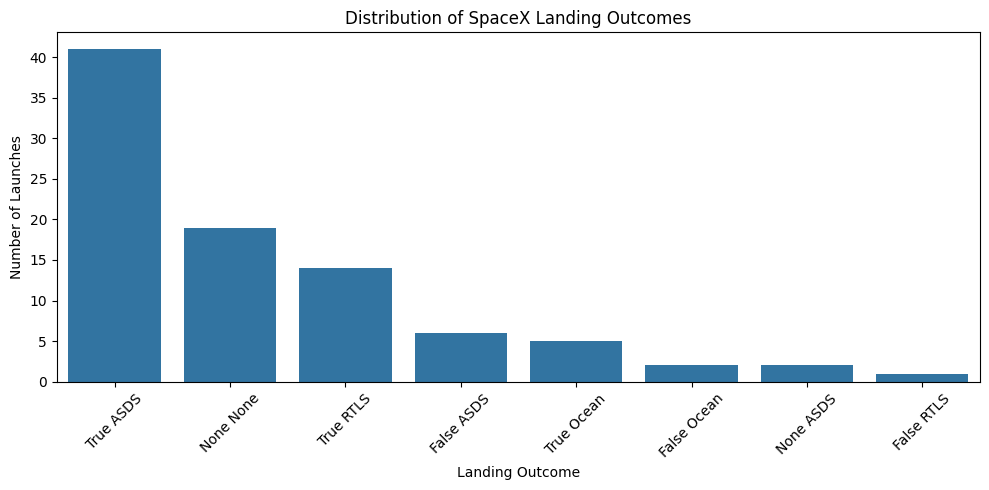

In [37]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="Outcome",
    order=df_clean["Outcome"].value_counts().index
)

plt.title("Distribution of SpaceX Landing Outcomes")
plt.xlabel("Landing Outcome")
plt.ylabel("Number of Launches")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

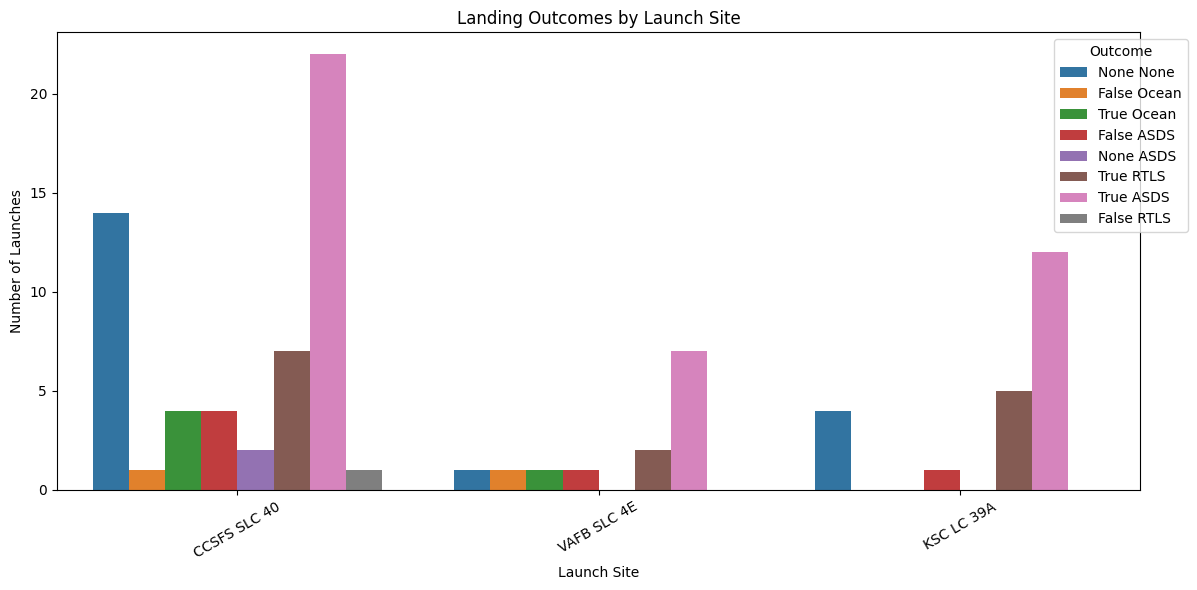

In [38]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_clean,
    x="LaunchSite",
    hue="Outcome"
)

plt.title("Landing Outcomes by Launch Site")
plt.xlabel("Launch Site")
plt.ylabel("Number of Launches")
plt.xticks(rotation=30)
plt.legend(title="Outcome", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

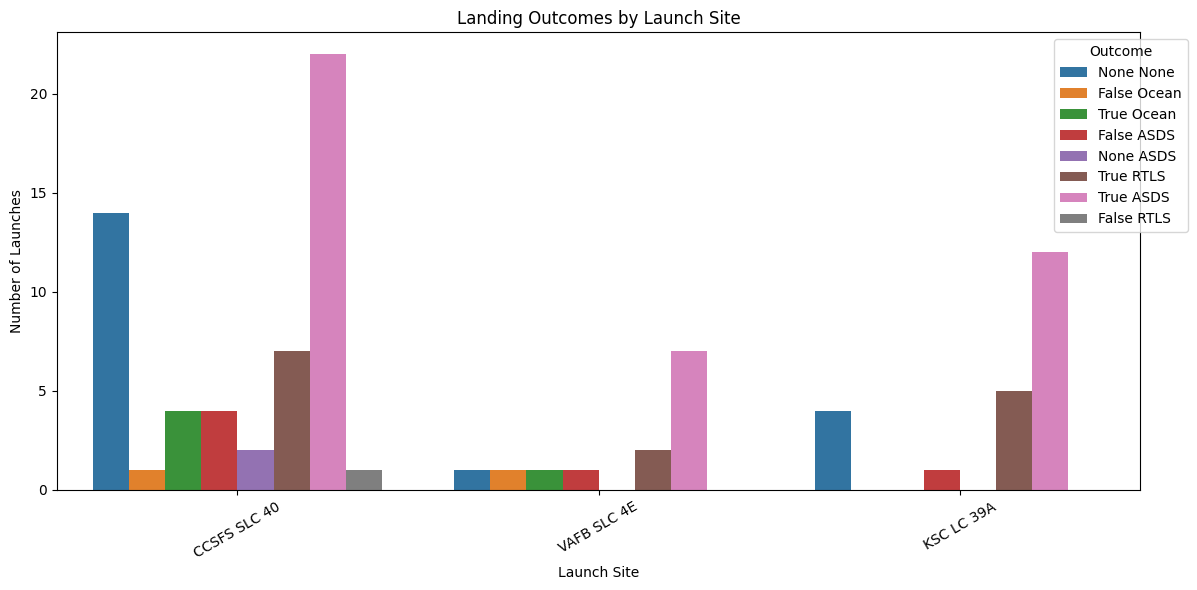

In [39]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_clean,
    x="LaunchSite",
    hue="Outcome"
)

plt.title("Landing Outcomes by Launch Site")
plt.xlabel("Launch Site")
plt.ylabel("Number of Launches")
plt.xticks(rotation=30)
plt.legend(title="Outcome", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [40]:
%pip install sqlalchemy

Note: you may need to restart the kernel to use updated packages.


In [41]:
import sqlite3
import pandas as pd
from pathlib import Path

print("SQL tools are ready!")

SQL tools are ready!


In [42]:
# Use the cleaned dataset if it exists
csv_path = Path("../data/spacex_launches_clean.csv")

if csv_path.exists():
    df_clean = pd.read_csv(csv_path)
else:
    csv_path = Path("../data/dataset_part_1.csv")
    df_clean = pd.read_csv(csv_path)

# Create a local database
conn = sqlite3.connect("../data/spacex_capstone.db")

# Store the dataset as a SQL table
df_clean.to_sql("SPACEX", conn, if_exists="replace", index=False)

print("Dataset loaded into SQL successfully!")
print(pd.read_sql_query("SELECT * FROM SPACEX LIMIT 5;", conn))

Dataset loaded into SQL successfully!
   FlightNumber        Date BoosterVersion  PayloadMass Orbit    LaunchSite  \
0             1  2010-06-04       Falcon 9          NaN   LEO  CCSFS SLC 40   
1             2  2012-05-22       Falcon 9        525.0   LEO  CCSFS SLC 40   
2             3  2013-03-01       Falcon 9        677.0   ISS  CCSFS SLC 40   
3             4  2013-09-29       Falcon 9        500.0    PO   VAFB SLC 4E   
4             5  2013-12-03       Falcon 9       3170.0   GTO  CCSFS SLC 40   

       Outcome  Flights  GridFins  Reused  Legs LandingPad  Block  \
0    None None        1         0       0     0       None    1.0   
1    None None        1         0       0     0       None    1.0   
2    None None        1         0       0     0       None    1.0   
3  False Ocean        1         0       0     0       None    1.0   
4    None None        1         0       0     0       None    1.0   

   ReusedCount Serial   Longitude   Latitude  
0            0  B0003  -8

In [43]:
query = """
SELECT COUNT(*) AS total_records
FROM SPACEX;
"""

display(pd.read_sql_query(query, conn))

,total_records
0,90


In [44]:
query = """
SELECT LaunchSite, COUNT(*) AS total_launches
FROM SPACEX
GROUP BY LaunchSite
ORDER BY total_launches DESC;
"""

display(pd.read_sql_query(query, conn))

,LaunchSite,total_launches
0,CCSFS SLC 40,55
1,KSC LC 39A,22
2,VAFB SLC 4E,13


In [45]:
print(df_clean.columns.tolist())

['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude']


In [46]:
print(df_clean.columns.tolist())

['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude']


In [47]:
%pip install folium

Note: you may need to restart the kernel to use updated packages.


In [48]:
import folium

print("Folium installed successfully!")

Folium installed successfully!


In [51]:
import folium
from pathlib import Path

# Create the map
launch_map = folium.Map(
    location=[28.5, -80.6],
    zoom_start=5
)

# Create the output folder automatically
output_dir = Path("../visualizations")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the map
output_file = output_dir / "spacex_launch_sites.html"
launch_map.save(str(output_file))

print("Map saved successfully!")
print("Saved location:", output_file.resolve())

Map saved successfully!
Saved location: C:\Users\acer\OneDrive\Desktop\capstone\SpaceX_Capstone\.venv\notebooks\visualizations\spacex_launch_sites.html
